# 04 · Integración y Conclusiones — Proyecto Final

**NOTEBOOK PRINCIPAL (MAESTRO) — Para presentación y defensa universitaria**

# Modernización del automóvil en Cuba: análisis del mercado automovilístico en La Habana

Asignatura: Introducción a la Ciencia de Datos (ICD)
Fase: 5 — Análisis Exploratorio (EDA), gráficos y conclusiones

Este notebook presenta la historia completa del proyecto, integrando los hallazgos de las tres fuentes de datos: mercado informal (Revolico), mercado formal (concesionarios e importadoras) y entrevistas a personas del mercado automotor.

| Dataset | Registros | Archivo |
|---|---|---|
| Mercado informal | 30 anuncios | `data/processed_final/anuncios_revolico_final.json` |
| Mercado formal | 10 entidades | `data/processed_final/mercado_formal_final.json` |
| Entrevistas | 30 personas | `data/processed_final/entrevistas_final.json` |
| Catálogos scrapeados | 65 modelos | `data/raw/catalogos_mercado_formal.json` |

## 1. Introducción y planteamiento del problema

### Contexto

El mercado automovilístico en La Habana, Cuba, atraviesa una situación singular marcada por:

- **Crisis energética**: apagones de más de 20 horas diarias en el sector residencial.
- **Escasez de combustible**: los precios de los combustibles se duplicaron en mayo de 2026 (gasolina especial a 2,60 USD/litro, diésel a 2,20 USD/litro).
- **Envejecimiento del parque automotor**: predominio de automóviles clásicos (almendrones) de las décadas de 1950-1980.
- **Llegada de marcas chinas**: Dongfeng, MG, Maxus, Geely, Foton, Bestune, DFSK.
- **Auge de vehículos eléctricos**: el 40% de las importaciones de vehículos en 2025 fueron eléctricos, pero por escasez de combustible, no por asequibilidad.
- **Bajo poder adquisitivo**: el salario medio ronda los 6.930 CUP, haciendo inalcanzable cualquier auto moderno para la mayoría de la población.

Los autos clásicos persisten no por gusto, sino por necesidad: son reparables con ingenio y piezas adaptadas.


### Preguntas de investigación

1. ¿Ha quedado atrás la época de los automóviles clásicos en La Habana?
2. ¿Qué tipos y marcas de automóviles modernos circulan actualmente con mayor presencia?
3. ¿Qué automóviles se están importando al país?
4. ¿Qué papel desempeñan los vehículos eléctricos? ¿Ventaja o problema?
5. ¿Cómo afecta la llegada de nuevas marcas al mercado informal cubano?

### Metodología

Se utilizaron **tres fuentes de datos complementarias**:

1. **Mercado informal (Revolico)**: 30 anuncios de venta de vehículos, con precio, marca, modelo, año, tipo de vehículo y motorización.
2. **Mercado formal**: 10 entidades (concesionarios e importadoras), con catálogos scrapeados de Dongfeng Cuba (49 modelos) y BDC ONE (16 modelos). Las otras 8 entidades no tienen catálogo público.
3. **Entrevistas**: 30 personas sobre percepciones de compra y venta de autos.

Herramientas: Python 3, pandas, matplotlib, seaborn. Formato de datos: JSON.


## 2. Librerías y carga de datos

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

FIG_DIR = Path("reports") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROC = BASE / "data" / "processed_final"
DATA_RAW = BASE / "data" / "raw"

def cargar_json(ruta):
    with open(ruta, encoding="utf-8") as archivo:
        return json.load(archivo)

# Cargar los tres datasets finales
anuncios = cargar_json(DATA_PROC / "anuncios_revolico_final.json")
formal = cargar_json(DATA_PROC / "mercado_formal_final.json")
entrevistas = cargar_json(DATA_PROC / "entrevistas_final.json")
catalogos = cargar_json(DATA_RAW / "catalogos_mercado_formal.json")

df_rev = pd.DataFrame(anuncios)
df_formal = pd.DataFrame(formal)
df_ent = pd.DataFrame(entrevistas)

print("=== CARGA DE DATOS ===")
print("Anuncios Revolico:", len(df_rev))
print("Entidades formales:", len(df_formal))
print("Entrevistas:", len(df_ent))
print("Catálogos:", len(catalogos), "entidades")

=== CARGA DE DATOS ===
Anuncios Revolico: 30
Entidades formales: 10
Entrevistas: 30
Catálogos: 3 entidades


## 3. Resumen de hallazgos — Mercado Informal (Revolico)

In [2]:
print("=== MERCADO INFORMAL: RESUMEN ===")
print("Total anuncios:", len(df_rev))
print("Precio promedio (USD):", round(df_rev['precio_anuncio'].mean(), 2))
print("Precio mediana (USD):", df_rev['precio_anuncio'].median())
print("Rango (USD):", df_rev['precio_anuncio'].min(), "-", df_rev['precio_anuncio'].max())
print("Año min-máx:", df_rev['ano'].min(), "-", df_rev['ano'].max())

print("\nMarcas:")
print(df_rev['marca'].value_counts().to_string())

print("\nTipo de vehículo:")
print(df_rev['tipo_vehiculo'].value_counts().to_string())

print("\nMotorización:")
print(df_rev['tipo_motorizacion'].value_counts().to_string())

=== MERCADO INFORMAL: RESUMEN ===
Total anuncios: 30
Precio promedio (USD): 31903.33
Precio mediana (USD): 31000.0
Rango (USD): 10000 - 100000
Año min-máx: 2009 - 2026

Marcas:
marca
Hyundai     19
Kia          5
Nissan       1
Honda        1
Toyota       1
BMW          1
Dongfeng     1
Geely        1

Tipo de vehículo:
tipo_vehiculo
SUV          15
Sedán         9
Hatchback     5
Deportivo     1

Motorización:
tipo_motorizacion
combustible    27
electrico       3


C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\4142899809.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_marcas.index, y=top_marcas.values, ax=axes[0,0], palette="viridis")
C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\4142899809.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=motor_counts.index, y=motor_counts.values, ax=axes[1,0], palette="Set2")
C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\4142899809.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tipo_counts.index, y=tipo_counts.values, ax=axes[1,1], 

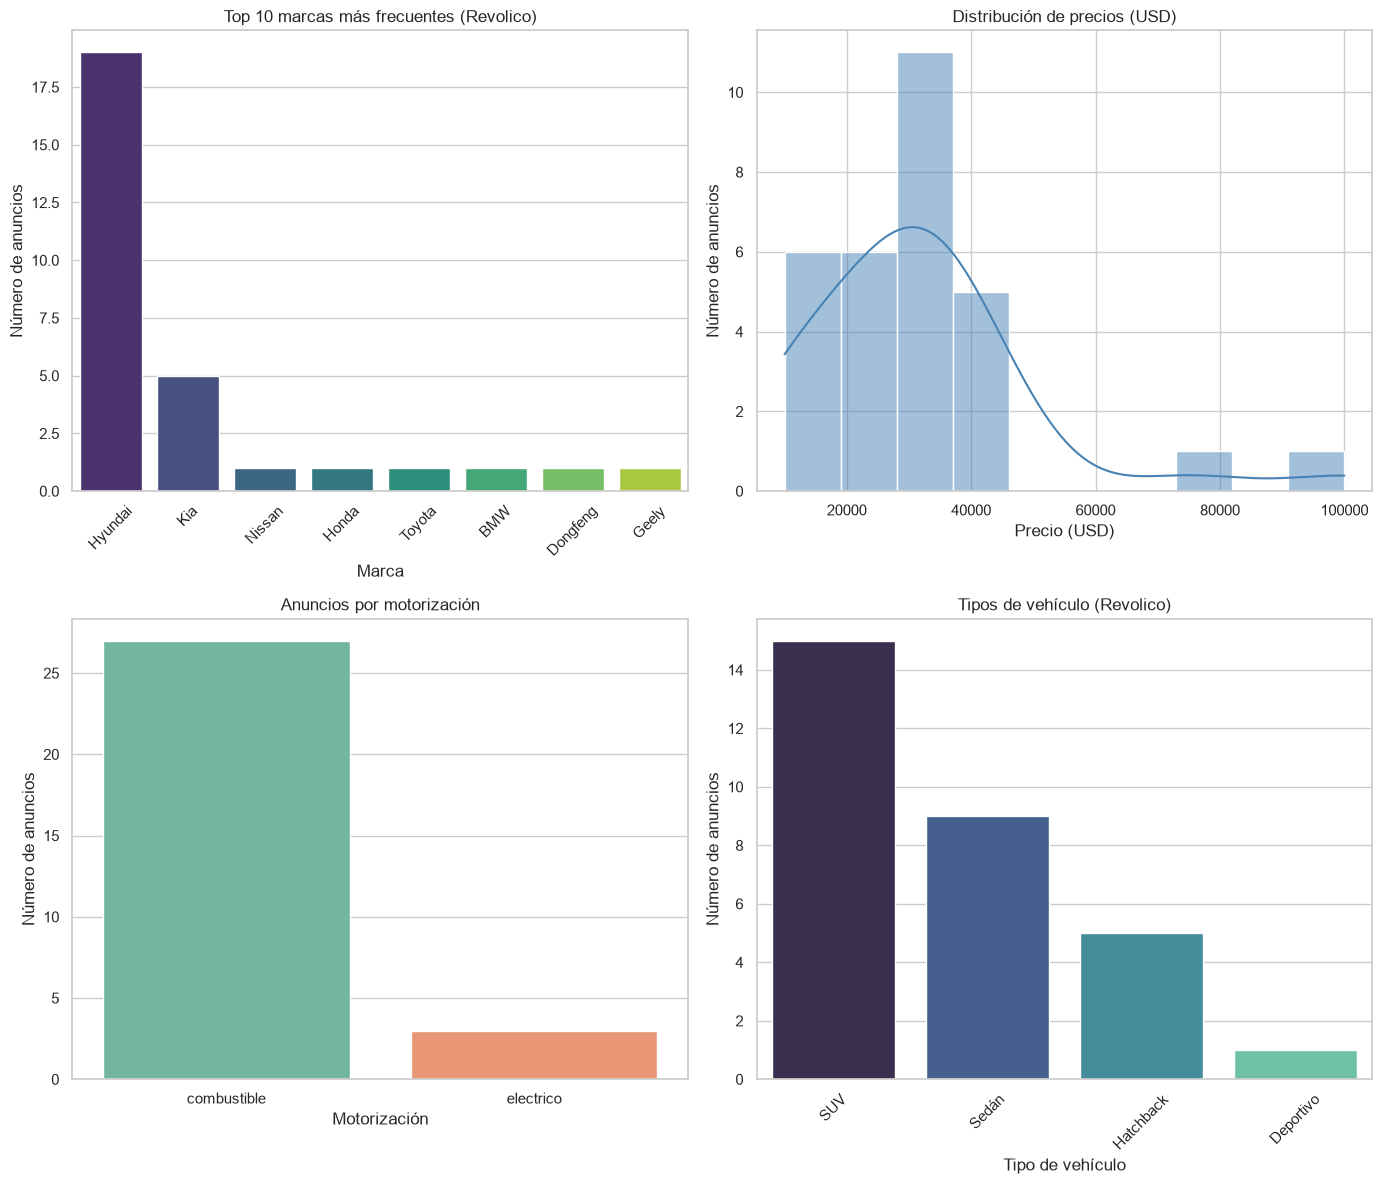

In [3]:
# Gráfico resumen informal
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

top_marcas = df_rev['marca'].value_counts().head(10)
sns.barplot(x=top_marcas.index, y=top_marcas.values, ax=axes[0,0], palette="viridis")
axes[0,0].set_title("Top 10 marcas más frecuentes (Revolico)")
axes[0,0].set_xlabel("Marca")
axes[0,0].set_ylabel("Número de anuncios")
axes[0,0].tick_params(axis='x', rotation=45)

sns.histplot(data=df_rev, x="precio_anuncio", kde=True, ax=axes[0,1], color="steelblue")
axes[0,1].set_title("Distribución de precios (USD)")
axes[0,1].set_xlabel("Precio (USD)")
axes[0,1].set_ylabel("Número de anuncios")

motor_counts = df_rev['tipo_motorizacion'].value_counts()
sns.barplot(x=motor_counts.index, y=motor_counts.values, ax=axes[1,0], palette="Set2")
axes[1,0].set_title("Anuncios por motorización")
axes[1,0].set_xlabel("Motorización")
axes[1,0].set_ylabel("Número de anuncios")

tipo_counts = df_rev['tipo_vehiculo'].value_counts()
sns.barplot(x=tipo_counts.index, y=tipo_counts.values, ax=axes[1,1], palette="mako")
axes[1,1].set_title("Tipos de vehículo (Revolico)")
axes[1,1].set_xlabel("Tipo de vehículo")
axes[1,1].set_ylabel("Número de anuncios")
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "f18_resumen_informal.png", dpi=150, bbox_inches="tight")
plt.show()

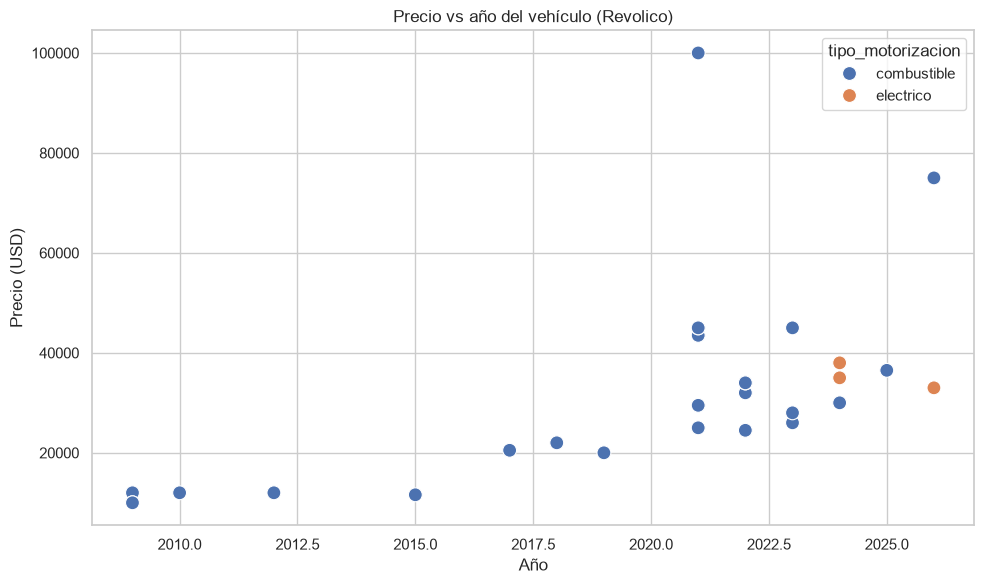

Vehículos eléctricos en Revolico: 3
   marca  modelo  ano  precio_anuncio               ubicacion
 Hyundai   Ioniq 2024           35000 La Habana, Habana Vieja
 Hyundai Ioniq 5 2024           38000        La Habana, Playa
Dongfeng     BOX 2026           33000        La Habana, Playa


In [4]:
# F5: Precio vs año
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_rev, x="ano", y="precio_anuncio", hue="tipo_motorizacion", 
                s=100, ax=ax, palette="deep")
ax.set_title("Precio vs año del vehículo (Revolico)")
ax.set_xlabel("Año")
ax.set_ylabel("Precio (USD)")
plt.tight_layout()
plt.savefig(FIG_DIR / "f05_precio_vs_ano_informal.png", dpi=150, bbox_inches="tight")
plt.show()

# Eléctricos en Revolico
ev_rev = df_rev[df_rev['tipo_motorizacion'] == 'electrico']
print("Vehículos eléctricos en Revolico:", len(ev_rev))
print(ev_rev[['marca', 'modelo', 'ano', 'precio_anuncio', 'ubicacion']].to_string(index=False))

### ¿Han quedado atrás los clásicos?

**Respuesta: No.** Los datos muestran que hay vehículos de todos los periodos: desde 2009 hasta 2026. Aunque hay presencia de modelos modernos (2021-2026 con 18 anuncios), también hay anuncios de vehículos de 2009-2015 (9 anuncios). Los clásicos persisten por necesidad económica y facilidad de reparación, no por preferencia.

## 4. Resumen de hallazgos — Mercado Formal

In [5]:
print("=== MERCADO FORMAL: RESUMEN ===")
print("Total entidades:", len(df_formal))
print("Tipos de entidad:")
print(df_formal['tipo_entidad'].value_counts().to_string())

con_cat = df_formal[df_formal['modelos_disponibles'].apply(len) > 0]
sin_cat = df_formal[df_formal['modelos_disponibles'].apply(len) == 0]
print("\nCon catálogo público:", len(con_cat))
print(con_cat[['id_entidad', 'nombre', 'tipo_entidad']].to_string(index=False))
print("\nSin catálogo público:", len(sin_cat))
print(sin_cat[['id_entidad', 'nombre', 'tipo_entidad']].to_string(index=False))

=== MERCADO FORMAL: RESUMEN ===
Total entidades: 10
Tipos de entidad:
tipo_entidad
comercializadora    4
importadora         4
concesionario       2

Con catálogo público: 2
   id_entidad        nombre  tipo_entidad
      BDC_ONE       BDC ONE concesionario
DONGFENG_CUBA Dongfeng Cuba concesionario

Sin catálogo público: 8
   id_entidad                                                                                               nombre     tipo_entidad
MCV_COMERCIAL                                                                                  MCV Comercial, S.A. comercializadora
         SASA                                                                   Servicios Automotores, S.A. (SASA) comercializadora
        DIVEP                                                                       Empresa Comercializadora DIVEP comercializadora
    IMPEXPORT                                                                                  IMPEXPORT, S.U.R.L.      importadora
    CIMEX_DTA  

In [6]:
# Extraer modelos de catálogos
todos_modelos = []
for e in catalogos:
    for m in e['modelos']:
        todos_modelos.append({
            'entidad': e['nombre_entidad'],
            'modelo': m['modelo'],
            'tipo_vehiculo': m['tipo_vehiculo'],
            'motorizacion': m['motorizacion'],
            'precio_eur': m['precio_original'],
            'autonomia_km': m.get('autonomia_km'),
        })
df_cat = pd.DataFrame(todos_modelos)

print("\nTotal modelos en catálogos:", len(df_cat))
print("\nPor entidad:")
print(df_cat['entidad'].value_counts().to_string())
print("\nPor motorización:")
print(df_cat['motorizacion'].value_counts().to_string())
print("\nPor tipo de vehículo:")
print(df_cat['tipo_vehiculo'].value_counts().to_string())

precios_eur = df_cat[df_cat['precio_eur'].notna()]['precio_eur']
if not precios_eur.empty:
    print("\nPrecio EUR: min=", precios_eur.min(), "| max=", precios_eur.max())
    print("Precio EUR promedio:", round(precios_eur.mean(), 2))


Total modelos en catálogos: 65

Por entidad:
entidad
Dongfeng Cuba    49
BDC ONE          16

Por motorización:
motorizacion
electrico    21
gasolina     21
hibrido      12
diesel       11

Por tipo de vehículo:
tipo_vehiculo
SUV                 20
Camión comercial    10
Van                  7
Pickup               7
Sedán                5
Microbús             5
Hatchback            4
Familiar             2
Monovolumen          2
Minibús              1
Panel                1
Deportivo            1

Precio EUR: min= 14849.0 | max= 99000.0
Precio EUR promedio: 31824.04


C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\3339615561.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mot_counts.index, y=mot_counts.values, ax=axes[1], palette="Set2")


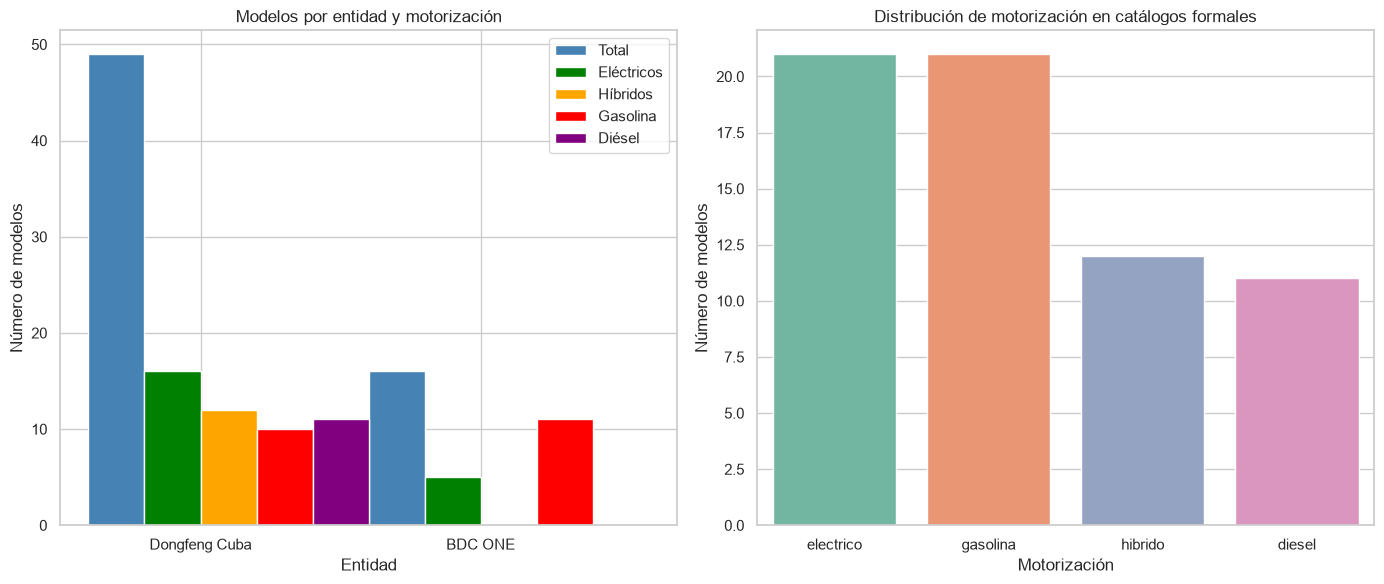

In [7]:
# Gráfico: modelos por entidad y motorización
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

entidades_cat = [e for e in catalogos if e['modelos']]
nombres = [e['nombre_entidad'] for e in entidades_cat]
n_modelos = [len(e['modelos']) for e in entidades_cat]
n_ev = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'electrico') for e in entidades_cat]
n_hib = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'hibrido') for e in entidades_cat]
n_gas = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'gasolina') for e in entidades_cat]
n_diesel = [sum(1 for m in e['modelos'] if m['motorizacion'] == 'diesel') for e in entidades_cat]

x = range(len(nombres))
width = 0.2
axes[0].bar([i - 1.5*width for i in x], n_modelos, width, label='Total', color='steelblue')
axes[0].bar([i - 0.5*width for i in x], n_ev, width, label='Eléctricos', color='green')
axes[0].bar([i + 0.5*width for i in x], n_hib, width, label='Híbridos', color='orange')
axes[0].bar([i + 1.5*width for i in x], n_gas, width, label='Gasolina', color='red')
axes[0].bar([i + 2.5*width for i in x], n_diesel, width, label='Diésel', color='purple')
axes[0].set_xlabel('Entidad')
axes[0].set_ylabel('Número de modelos')
axes[0].set_title('Modelos por entidad y motorización')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(nombres)
axes[0].legend()

mot_counts = df_cat['motorizacion'].value_counts()
sns.barplot(x=mot_counts.index, y=mot_counts.values, ax=axes[1], palette="Set2")
axes[1].set_title('Distribución de motorización en catálogos formales')
axes[1].set_xlabel('Motorización')
axes[1].set_ylabel('Número de modelos')

plt.tight_layout()
plt.savefig(FIG_DIR / "f19_resumen_formal.png", dpi=150, bbox_inches="tight")
plt.show()

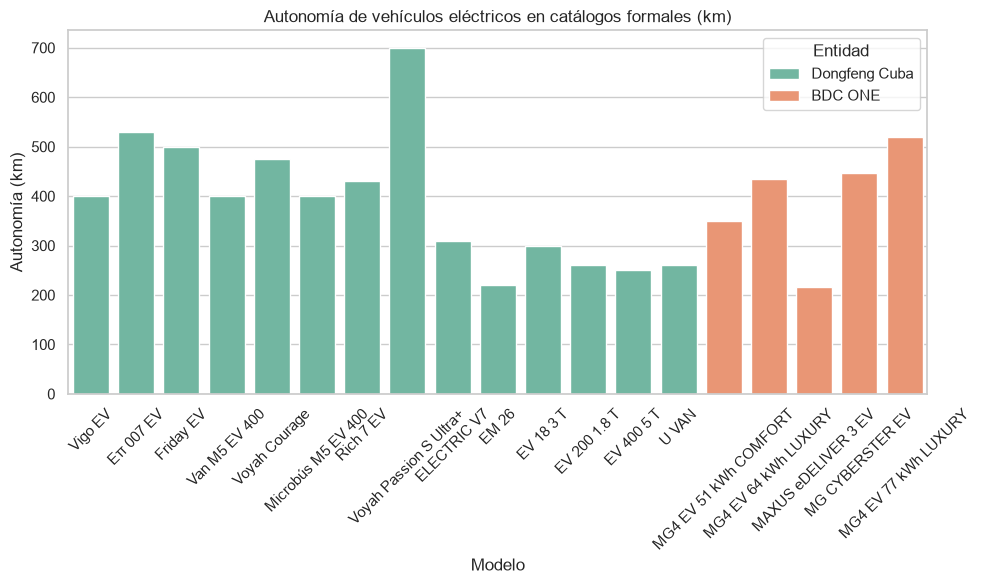

Vehículos eléctricos en catálogos: 21
Con autonomía publicada: 19


In [8]:
# F9: Autonomía de eléctricos formales
ev_aut = df_cat[df_cat['motorizacion'] == 'electrico']
ev_aut = ev_aut[ev_aut['autonomia_km'].notna()]

if not ev_aut.empty:
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=ev_aut, x='modelo', y='autonomia_km', hue='entidad', ax=ax, palette="Set2")
    ax.set_title('Autonomía de vehículos eléctricos en catálogos formales (km)')
    ax.set_xlabel('Modelo')
    ax.set_ylabel('Autonomía (km)')
    plt.xticks(rotation=45)
    ax.legend(title='Entidad')
    plt.tight_layout()
    plt.savefig(FIG_DIR / "f10_autonomia_ev_formal.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Vehículos eléctricos en catálogos:", len(df_cat[df_cat['motorizacion'] == 'electrico']))
print("Con autonomía publicada:", len(ev_aut))

### Oferta institucional

- **Dongfeng Cuba**: 49 modelos (16 eléctricos, 12 híbridos, 10 gasolina, 11 diésel). Precios: 15.900 – 99.000 EUR.
- **BDC ONE**: 16 modelos (5 eléctricos, 11 gasolina). Precios: 14.849 – 67.135 EUR.
- **8 entidades sin catálogo público**: SASA, DIVEP, IMPEXPORT, CIMEX_DTA, PALCO, TRANSIMPORT, TRADEX y MCV Comercial.
- **15 modelos de Dongfeng** tienen precio "A consultar" (sin precio público).
- Los precios formales **no incluyen impuestos** (Resolución 172/2026).

## 5. Resumen de hallazgos — Entrevistas

In [9]:
print("=== ENTREVISTAS: RESUMEN ===")
print("Total entrevistas:", len(df_ent))
print("\nPor zona:")
print(df_ent['zona'].value_counts().to_string())

# Opinión sobre eléctricos
opiniones = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('opinion_vehiculos_electricos'):
        opiniones.append(r['respuestas']['opinion_vehiculos_electricos'])
print("\nOpinión sobre vehículos eléctricos:")
print(str(dict(Counter(opiniones))))

# Predominio de clásicos
clasicos = []
for r in entrevistas:
    if r.get('respuestas') and 'predominio_autos_clasicos' in r['respuestas']:
        clasicos.append(r['respuestas']['predominio_autos_clasicos'])
print("\n¿Predominan los autos clásicos?")
print(str(dict(Counter(clasicos))))

# Tipo de vehículo observado
tipo_obs = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('tipo_vehiculo_observado'):
        tipo_obs.append(r['respuestas']['tipo_vehiculo_observado'])
print("\nTipo de vehículo observado:")
print(str(dict(Counter(tipo_obs))))

# Marcas modernas mencionadas
todas_marcas = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('marcas_modernas_observadas'):
        todas_marcas.extend(r['respuestas']['marcas_modernas_observadas'])
print("\nMarcas modernas más mencionadas:")
for marca, cnt in Counter(todas_marcas).most_common(10):
    print('  ' + marca + ': ' + str(cnt))

=== ENTREVISTAS: RESUMEN ===
Total entrevistas: 30

Por zona:
zona
Alamar           20
Vedado            3
Guanabacoa        3
Playa             2
Cerro             1
Centro Habana     1

Opinión sobre vehículos eléctricos:
{'Mala': 26, 'Buena': 2, 'Indiferente': 2}

¿Predominan los autos clásicos?
{True: 25, False: 5}

Tipo de vehículo observado:
{'Clásicos': 21, 'Modernos': 9}

Marcas modernas más mencionadas:
  Kia: 28
  Hyundai: 25
  Foton: 14
  Bestune: 11
  Mercedes: 5
  DFSK: 3
  Geely: 2
  BMW: 1
  Toyota: 1


C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\4144430391.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(op_counts.keys()), y=list(op_counts.values()), ax=axes[0,0], palette="Set2")
C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\4144430391.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(tipo_counts.keys()), y=list(tipo_counts.values()), ax=axes[0,1], palette="rocket")
C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\4144430391.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[m[0] for m in top10_m], y=[m[

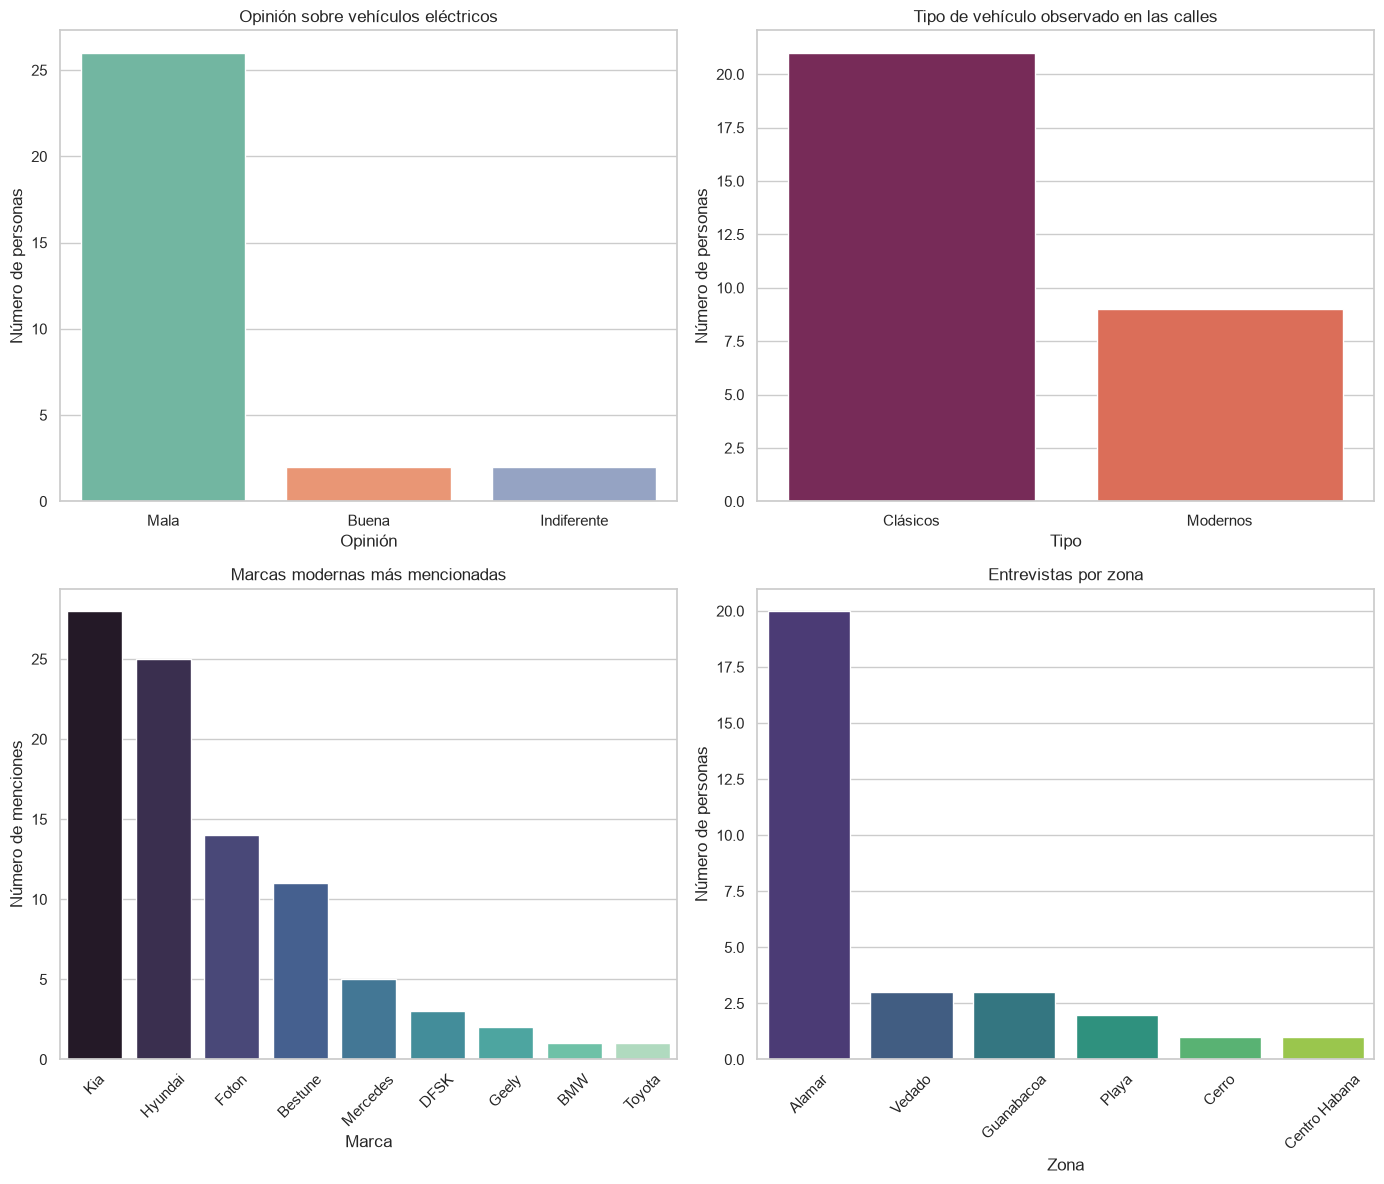

In [10]:
# Gráfico: percepciones de entrevistas
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

op_counts = Counter(opiniones)
sns.barplot(x=list(op_counts.keys()), y=list(op_counts.values()), ax=axes[0,0], palette="Set2")
axes[0,0].set_title("Opinión sobre vehículos eléctricos")
axes[0,0].set_xlabel("Opinión")
axes[0,0].set_ylabel("Número de personas")

tipo_counts = Counter(tipo_obs)
sns.barplot(x=list(tipo_counts.keys()), y=list(tipo_counts.values()), ax=axes[0,1], palette="rocket")
axes[0,1].set_title("Tipo de vehículo observado en las calles")
axes[0,1].set_xlabel("Tipo")
axes[0,1].set_ylabel("Número de personas")

marcas_cont = Counter(todas_marcas)
top10_m = marcas_cont.most_common(10)
sns.barplot(x=[m[0] for m in top10_m], y=[m[1] for m in top10_m], ax=axes[1,0], palette="mako")
axes[1,0].set_title("Marcas modernas más mencionadas")
axes[1,0].set_xlabel("Marca")
axes[1,0].set_ylabel("Número de menciones")
axes[1,0].tick_params(axis='x', rotation=45)

zona_counts = df_ent['zona'].value_counts()
sns.barplot(x=zona_counts.index, y=zona_counts.values, ax=axes[1,1], palette="viridis")
axes[1,1].set_title("Entrevistas por zona")
axes[1,1].set_xlabel("Zona")
axes[1,1].set_ylabel("Número de personas")
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(FIG_DIR / "f20_resumen_entrevistas.png", dpi=150, bbox_inches="tight")
plt.show()

### Percepciones clave

- **83% (25/30)** creen que predominan los autos clásicos en las calles.
- **87% (26/30)** tienen opinión 'Mala' sobre vehículos eléctricos.
- **Kia y Hyundai** son las marcas modernas más mencionadas.
- En Alamar (20 entrevistas), todos creen que predominan los clásicos.
- En Vedado y Playa hay más apertura, pero persisten dudas por la infraestructura de carga.

## 6. Integración y triangulación de fuentes

In [11]:
# Preparar datos para comparación
marcas_rev = set(df_rev['marca'])

# Marcas en entrevistas
todas_marcas_ent = []
for r in entrevistas:
    if r.get('respuestas') and r['respuestas'].get('marcas_modernas_observadas'):
        todas_marcas_ent.extend(r['respuestas']['marcas_modernas_observadas'])
marcas_ent = set(todas_marcas_ent)

# Marcas en catálogos formales
marcas_form = set()
for _, r in df_formal.iterrows():
    marcas_form.update(r['marcas_comercializadas'])

print("=== MARCAS POR FUENTE ===")
print("Revolico:", sorted(marcas_rev))
print("Entrevistas:", sorted(marcas_ent))
print("Mercado formal:", sorted(marcas_form))

print("\n=== INTERSECCIONES ===")
print("Revolico ∩ Entrevistas:", sorted(marcas_rev & marcas_ent))
print("Revolico ∩ Formal:", sorted(marcas_rev & marcas_form))
print("Entrevistas ∩ Formal:", sorted(marcas_ent & marcas_form))
print("Tres fuentes:", sorted(marcas_rev & marcas_ent & marcas_form))

=== MARCAS POR FUENTE ===
Revolico: ['BMW', 'Dongfeng', 'Geely', 'Honda', 'Hyundai', 'Kia', 'Nissan', 'Toyota']
Entrevistas: ['BMW', 'Bestune', 'DFSK', 'Foton', 'Geely', 'Hyundai', 'Kia', 'Mercedes', 'Toyota']
Mercado formal: ['Dongfeng', 'MG', 'Maxus', 'Mitsubishi']

=== INTERSECCIONES ===
Revolico ∩ Entrevistas: ['BMW', 'Geely', 'Hyundai', 'Kia', 'Toyota']
Revolico ∩ Formal: ['Dongfeng']
Entrevistas ∩ Formal: []
Tres fuentes: []


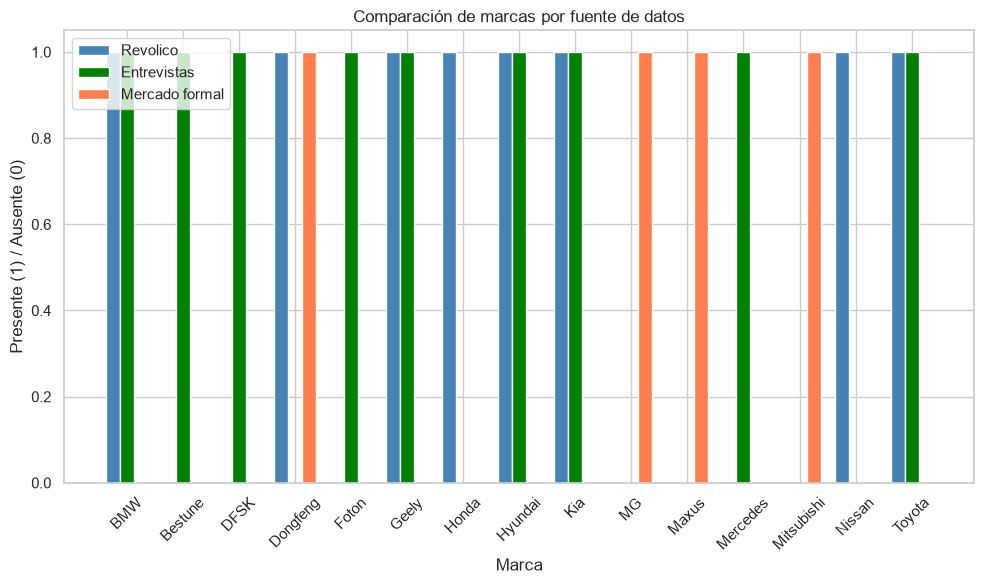

In [12]:
# Gráfico F15: Comparación de marcas por fuente
fig, ax = plt.subplots(figsize=(10, 6))

todas_marcas_unicas = sorted(marcas_rev | marcas_ent | marcas_form)
conteo_rev = [1 if m in marcas_rev else 0 for m in todas_marcas_unicas]
conteo_ent = [1 if m in marcas_ent else 0 for m in todas_marcas_unicas]
conteo_form = [1 if m in marcas_form else 0 for m in todas_marcas_unicas]

x = range(len(todas_marcas_unicas))
width = 0.25
ax.bar([i - width for i in x], conteo_rev, width, label='Revolico', color='steelblue')
ax.bar(x, conteo_ent, width, label='Entrevistas', color='green')
ax.bar([i + width for i in x], conteo_form, width, label='Mercado formal', color='coral')

ax.set_xlabel('Marca')
ax.set_ylabel('Presente (1) / Ausente (0)')
ax.set_title('Comparación de marcas por fuente de datos')
ax.set_xticks(list(x))
ax.set_xticklabels(todas_marcas_unicas, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "f15_comparacion_marcas.png", dpi=150, bbox_inches="tight")
plt.show()

C:\Users\jorge\AppData\Local\Temp\ipykernel_27004\2620205155.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_comp, x='fuente', y='precio', ax=ax, palette="Set2")


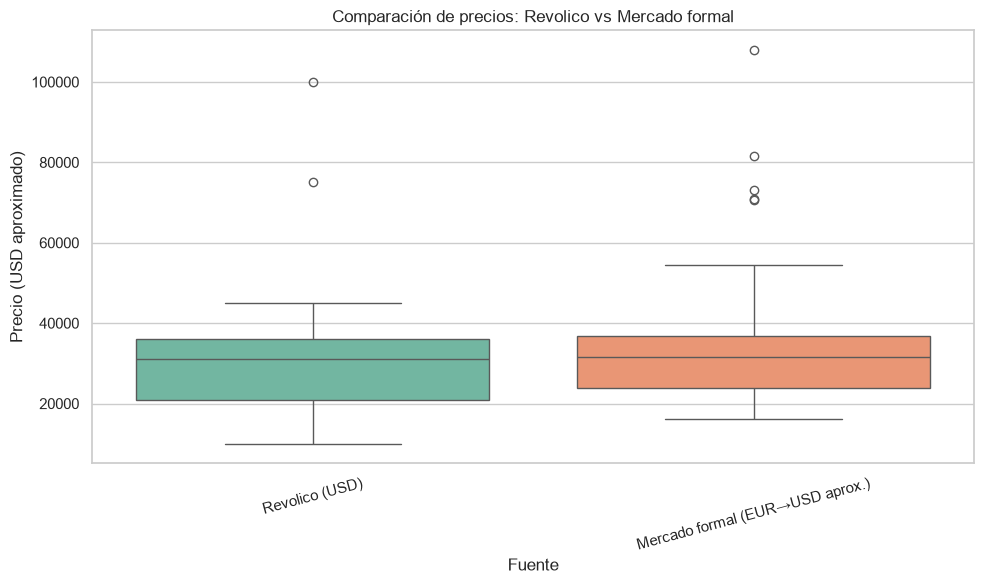

Precio promedio Revolico (USD): 31903.33
Precio promedio formal (EUR): 31824.04
Precio promedio formal (USD aprox.): 34688.2
Nota: precios formales NO incluyen impuestos


In [13]:
# Gráfico F16: Comparación de precios
fig, ax = plt.subplots(figsize=(10, 6))

precios_rev = df_rev['precio_anuncio']  # USD
precios_eur = df_cat[df_cat['precio_eur'].notna()]['precio_eur']  # EUR
precios_usd_aprox = precios_eur * 1.09  # Conversión aproximada EUR -> USD

datos_comp = []
for p in precios_rev:
    datos_comp.append({'fuente': 'Revolico (USD)', 'precio': p})
for p in precios_usd_aprox:
    datos_comp.append({'fuente': 'Mercado formal (EUR→USD aprox.)', 'precio': p})
df_comp = pd.DataFrame(datos_comp)

sns.boxplot(data=df_comp, x='fuente', y='precio', ax=ax, palette="Set2")
ax.set_title("Comparación de precios: Revolico vs Mercado formal")
ax.set_xlabel('Fuente')
ax.set_ylabel('Precio (USD aproximado)')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig(FIG_DIR / "f16_comparacion_precios.png", dpi=150, bbox_inches="tight")
plt.show()

print("Precio promedio Revolico (USD):", round(precios_rev.mean(), 2))
print("Precio promedio formal (EUR):", round(precios_eur.mean(), 2))
print("Precio promedio formal (USD aprox.):", round(precios_usd_aprox.mean(), 2))
print("Nota: precios formales NO incluyen impuestos")

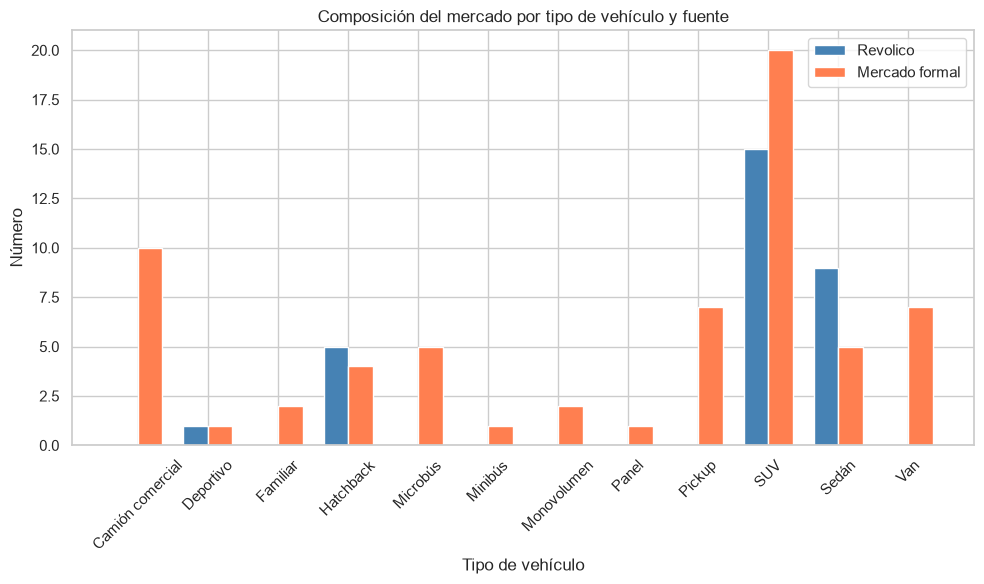

In [14]:
# Gráfico F17: Composición del mercado por tipo y fuente
fig, ax = plt.subplots(figsize=(10, 6))

tipo_rev = df_rev['tipo_vehiculo'].value_counts()
tipo_form = df_cat['tipo_vehiculo'].value_counts()

todos_tipos = sorted(set(tipo_rev.index) | set(tipo_form.index))
valores_rev = [tipo_rev.get(t, 0) for t in todos_tipos]
valores_form = [tipo_form.get(t, 0) for t in todos_tipos]

x = range(len(todos_tipos))
width = 0.35
ax.bar([i - width/2 for i in x], valores_rev, width, label='Revolico', color='steelblue')
ax.bar([i + width/2 for i in x], valores_form, width, label='Mercado formal', color='coral')

ax.set_xlabel('Tipo de vehículo')
ax.set_ylabel('Número')
ax.set_title('Composición del mercado por tipo de vehículo y fuente')
ax.set_xticks(list(x))
ax.set_xticklabels(todos_tipos, rotation=45)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "f17_composicion_tipo.png", dpi=150, bbox_inches="tight")
plt.show()

### Convergencias y divergencias

**Convergencias:**
- Hyundai y Kia aparecen en Revolico y en las entrevistas como marcas modernas más frecuentes.
- Dongfeng aparece tanto en el mercado formal como en el informal.
- Los SUV son frecuentes tanto en Revolico como en los catálogos formales.

**Divergencias:**
- MG, Maxus y Mitsubishi están en el formal pero NO aparecen en los anuncios de Revolico.
- Los vehículos eléctricos son raros en Revolico (3/30) pero abundan en los catálogos formales (21/65).
- Las entrevistas son escépticas sobre eléctricos (87% opinión 'Mala'), aunque el formal ofrece muchos modelos eléctricos.
- Los precios formales (en EUR, sin impuestos) son generalmente más altos que los informales (en USD).

## 7. Tendencias identificadas

### Tendencias principales

1. **Crecimiento de marcas chinas**: Dongfeng, Bestune, Geely y Foton aparecen tanto en el mercado informal como en el formal, desplazando gradualmente a marcas tradicionales.

2. **Auge de eléctricos por necesidad, no por preferencia**: los eléctricos crecen por la escasez de combustible, pero su adopción está frenada por los apagones y la falta de infraestructura de carga.

3. **Persistencia de los clásicos**: los autos antiguos siguen predominando por necesidad económica y facilidad de reparación, no por preferencia estética.

4. **Brecha formal–informal**: el mercado formal opera en EUR con catálogos institucionales y precios sin impuestos; el informal opera en USD con ventas entre particulares.

5. **Escepticismo social**: la mayoría de las personas entrevistadas tiene una opinión negativa sobre los vehículos eléctricos, especialmente en zonas periféricas como Alamar.

## 8. Respuestas a las preguntas de investigación

### 1. ¿Ha quedado atrás la época de los automóviles clásicos en La Habana?

**Respuesta: No.** Los datos de Revolico muestran vehículos desde 2009 hasta 2026, con presencia significativa de modelos anteriores a 2015 (9 anuncios, 30%). Las entrevistas confirman que el 83% de las personas perciben que predominan los clásicos en las calles. Los clásicos persisten por necesidad económica y facilidad de reparación.

### 2. ¿Qué tipos y marcas de automóviles modernos circulan con mayor presencia?

**Respuesta:** Hyundai es la marca más frecuente en Revolico (19 de 30 anuncios, 63%), seguida de Kia (5). Los SUV son el tipo más común (50%). En las entrevistas, Kia y Hyundai son las marcas modernas más mencionadas. En el mercado formal, Dongfeng y MG (a través de BDC ONE) son las principales marcas chinas presentes.

### 3. ¿Qué automóviles se están importando?

**Respuesta:** Según los catálogos formales, se importan vehículos de Dongfeng (49 modelos: eléctricos, híbridos, gasolina y diésel) y de MG, Maxus y Mitsubishi a través de BDC ONE (16 modelos). El 40% de las importaciones de 2025 fueron vehículos eléctricos.

### 4. ¿Qué papel desempeñan los vehículos eléctricos? ¿Ventaja o problema?

**Respuesta: Problema, por ahora.** Aunque los eléctricos son cada vez más visibles en los catálogos formales (21 de 65 modelos), su adopción en el mercado informal es muy limitada (3 de 30 anuncios). Las entrevistas muestran un escepticismo abrumador (87% opinión 'Mala'), relacionado con los apagones (más de 20 horas de interrupción eléctrica) y la falta de infraestructura de carga. Los eléctricos son una respuesta a la escasez de combustible, no una opción asequible: cuestan aproximadamente el doble que los de combustión.

### 5. ¿Cómo afecta la llegada de nuevas marcas al mercado informal cubano?

**Respuesta:** Las marcas chinas (Dongfeng, Geely, Bestune, Foton) están entrando tanto en el mercado formal como en el informal. Sin embargo, el impacto es aún limitado: solo 1 de 30 anuncios en Revolico es de una marca china (Dongfeng BOX). Las marcas tradicionales (Hyundai, Kia) siguen dominando el informal. Las marcas del formal (MG, Maxus, Mitsubishi) aún no se han reflejado en el mercado informal de segunda mano.

## 9. Limitaciones del estudio

- **Muestra pequeña**: 30 anuncios y 30 entrevistas permiten describir, no generalizar.
- **Cobertura geográfica**: las entrevistas están concentradas en Alamar (20 de 30).
- **Precios informales**: son precios pedidos, no de cierre real.
- **Precios formales**: no incluyen impuestos y 15 modelos no tienen precio público.
- **Año-modelo formal**: los catálogos no especifican año por vehículo.
- **Plataforma única**: Revolico no representa todo el mercado informal.
- **Entrevistas declarativas**: respuestas no verificables objetivamente.

## 10. Recomendaciones para futuros estudios

- Ampliar la muestra de anuncios y entrevistas.
- Incluir más plataformas de venta informal además de Revolico.
- Recopilar precios de cierre reales, no solo precios pedidos.
- Estudiar el impacto de los precios de combustibles en la decisión de compra.
- Analizar políticas de importación y aranceles sobre vehículos eléctricos.
- Estudiar la infraestructura de carga eléctrica en La Habana.
- Incluir más zonas geográficas en las entrevistas.

## 11. Cierre

La modernización del automóvil en Cuba está en marcha, pero es una modernización **asimetrónica**: el mercado formal ofrece vehículos eléctricos y modernos de marcas chinas, mientras que el mercado informal sigue dominado por Hyundai y Kia con precios en USD. Los vehículos eléctricos están presentes en los catálogos pero enfrentan una barrera casi insalvable: la falta de electricidad estable. Los autos clásicos persisten no por nostalgia, sino porque son la única opción viable para la mayoría de los habaneros. La transición hacia una movilidad moderna requerirá no solo la llegada de nuevos vehículos, sino una solución estructural a la crisis energética del país.